# 05 · Apertus als drittes Modell (nachträgliche Erweiterung)

**Status:** Erweiterung *nach* dem Freeze (Protokoll `3942fc49…`), auf Wunsch der Betreuung (Feedback 30.10.2026).
Nicht im vorab festgelegten Analyseplan, alles hier ist **explorativ**.

- Modell: `swiss-ai/apertus-v1.5-70b` über Public AI, Temperatur 0, Thinking aus, dieselben 5 Prompts (Fingerprint `37d7e209e7fc9178`).
- Nur MNLI-Test (327) und SNLI-Stichprobe (300). Kein Train/Dev, deshalb werden **keine** Bewerter auf Apertus trainiert.
- Unterschied zu GPT/Claude: Die Feldnamen kamen per Text-Anweisung am Ende der System-Nachricht, weil Public AI `json_schema` blockiert.
- Der eingefrorene Code wird nur **gelesen**: Features, Bäume, Regeln und Metriken kommen unverändert aus `src/`. Neue Dateien landen nur in `extension_apertus/results/`.

**Vorab festgehaltene Erwartung** (aufgeschrieben, bevor die menschlichen Stimmen ausgewertet wurden):
die eingefrorenen Risiko-Bewerter übertragen schlecht auf Apertus, weil GPT-Fehler bei der Antwort «neutral» lagen, Apertus aber vor allem zu oft «entailment» sagt und dabei sehr sicher ist.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/project.json").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "extension_apertus"))
sys.path.insert(0, str(ROOT / "tools"))
import pandas as pd
from IPython.display import display, Image
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 220)
import evaluate_apertus as ev
import verify_freeze
print("Projekt:", ROOT.name)

Projekt: uncertainty_project


## 1 · Antworten sammeln (bereits erledigt, 7.11.2026)

Nur zur Dokumentation. **Nicht nochmal ausführen**, das kostet Geld und ist nicht nötig: fertige Antworten liegen in `extension_apertus/outputs_v2/`.

In [2]:
# %run ../extension_apertus/run_apertus.py --check   # 1 Testanfrage
# %run ../extension_apertus/run_apertus.py           # voller Lauf, setzt nach Abbruch fort

## 2 · Siegel vorher prüfen

In [3]:
record, changed, missing, added = verify_freeze.check(ROOT)
assert not (changed or missing or added), "Eingefrorene Dateien wurden verändert. Stopp."
print(f"Siegel OK: Protokoll {record['protocol_id'][:16]}, {len(record['files'])} Dateien unverändert.")

Siegel OK: Protokoll 3942fc496262a9b3, 12742 Dateien unverändert.


## 3 · Auswertung

Dauert ca. 5 Minuten (500 Bootstrap-Wiederholungen wie im eingefrorenen Code). Für einen schnellen Probelauf `QUICK = True` setzen.

Zuerst werden die Notebook-03-Zahlen von GPT und Claude neu berechnet und mit den gespeicherten Tabellen verglichen.
Stimmen sie nicht, bricht die Auswertung ab (dann ist die Umgebung anders als beim Freeze).

In [4]:
QUICK = False
res = ev.run(quick=QUICK)
rep = pd.concat([r["reproduction"] for r in res.values()])
print("Notebook 03 reproduziert:", bool(rep.ok.all()), f"({len(rep)} Vergleiche)")
display(rep.groupby(["split", "model", "rows"]).max_abs_diff.max().to_frame())

Notebook 03 reproduziert: True (172 Vergleiche)


max_abs_diff
split model  rows                     
shift claude exact            0.000547
             raw_signals      0.000047
      gpt    exact            0.000119
             raw_signals      0.000706
test  claude exact            0.002303
             raw_signals      0.000136
      gpt    exact            0.000179
             raw_signals      0.000130

Spearman-Korrelationen und die AUROCs der Rohsignale (Entropie, MI, ...) dürfen sich zwischen Computern in der 3. bis 4. Nachkommastelle unterscheiden, weil fast gleiche Werte je nach Rechner anders sortiert werden. Gelernte Bewerter, Regeln und Fehlermasse müssen exakt stimmen.

## 4 · Ergebnisse pro Teil

Alle Vergleiche laufen auf den **gemeinsamen Fällen** (Fälle, bei denen Apertus alle fünf Prompts gültig beantwortet hat). Deshalb weichen die GPT- und Claude-Zahlen leicht von Notebook 03 ab.

In [5]:
COLS_RAW = ["model", "n", "majority_agreement", "js_divergence", "correctness_ece", "entropy_spearman", "mean_confidence",
            "label_flip_rate", "answer_share_e", "answer_share_n", "answer_share_c"]
COLS_DIS = ["model", "signal", "auroc_debatable", "auroc_debatable_ci_low", "auroc_debatable_ci_high",
            "auroc_error_on_clear_cases", "auroc_error_on_clear_ci_low", "auroc_error_on_clear_ci_high", "spearman_human_entropy"]
for split, out in res.items():
    m = out["meta"]
    print(f"\n==================== {m['name']} ====================")
    print(f"Apertus komplett: {m['apertus_complete']}/{m['cases']} Fälle | ungültige Antworten: {m['invalid_answers']}/{m['requests']} | "
          f"klare Fälle: {m['clear_cases']} (davon {m['apertus_clear_deviations']} Apertus-Abweichungen) | debatable: {m['debatable_cases']}")
    print("\nA · Rohvergleich der drei Modelle")
    display(out["raw_comparison"][COLS_RAW].round(3))
    print("Gepaarte Unterschiede (Bootstrap über Prämissen-Gruppen)")
    display(out["paired_differences"].round(3))
    print("Rohsignale: debatable und Fehler auf klaren Fällen (AUROC)")
    display(out["raw_dissociation"][COLS_DIS].round(3))
    print("\nB · Transfer: eingefrorene GPT- und Claude-Bewerter unverändert auf Apertus")
    display(out["transfer_summary"].round(3))
    print("Gelerntes (übertragenes) Signal minus Apertus-Rohsignal")
    display(out["transfer_vs_raw"].round(3))
    for src in ("gpt", "claude"):
        print(f"Spezialisierung (wie primäre Analyse), {src}-Bewerter auf Apertus")
        display(out[f"{src}_to_apertus_specialisation"].drop(columns="question").round(3))
    print("\nC · Fehlerprofil auf klaren Fällen: bei welcher Antwort liegen die Abweichungen?")
    display(out["error_profile"].round(3))
    print("\nD · Ungültige Antworten (Fälle ausgeschlossen)")
    display(out["invalid_cases"].round(3))


==================== MNLI-Test ====================
Apertus komplett: 310/327 Fälle | ungültige Antworten: 42/1635 | klare Fälle: 85 (davon 19 Apertus-Abweichungen) | debatable: 173

A · Rohvergleich der drei Modelle


,model,n,majority_agreement,js_divergence,correctness_ece,entropy_spearman,mean_confidence,label_flip_rate,answer_share_e,answer_share_n,answer_share_c
0,gpt,310,0.577,0.144,0.266,0.100,0.840,0.106,0.177,0.703,0.119
1,claude,310,0.648,0.074,0.043,0.095,0.661,0.181,0.206,0.548,0.245
2,apertus,310,0.645,0.191,0.193,0.141,0.838,0.177,0.503,0.184,0.313


Gepaarte Unterschiede (Bootstrap über Prämissen-Gruppen)


,comparison,metric,estimate,ci_95_low,ci_95_high,better_if
0,apertus_minus_gpt,majority_agreement,0.068,-0.013,0.143,positive
1,apertus_minus_gpt,js_divergence,0.046,0.024,0.067,negative
2,apertus_vs_gpt,same_answer_rate,0.439,NaN,NaN,descriptive
3,apertus_minus_claude,majority_agreement,-0.003,-0.074,0.071,positive
4,apertus_minus_claude,js_divergence,0.116,0.095,0.137,negative
5,apertus_vs_claude,same_answer_rate,0.555,NaN,NaN,descriptive
6,gpt_vs_claude,same_answer_rate,0.748,NaN,NaN,descriptive


Rohsignale: debatable und Fehler auf klaren Fällen (AUROC)


,model,signal,auroc_debatable,auroc_debatable_ci_low,auroc_debatable_ci_high,auroc_error_on_clear_cases,auroc_error_on_clear_ci_low,auroc_error_on_clear_ci_high,spearman_human_entropy
0,gpt,model_total_entropy,0.532,0.463,0.599,0.780,0.659,0.892,0.100
1,gpt,model_expected_entropy,0.532,0.466,0.597,0.777,0.662,0.892,0.092
2,gpt,model_epistemic_mi,0.534,0.462,0.602,0.761,0.638,0.864,0.100
3,gpt,model_credal_width,0.529,0.458,0.593,0.801,0.685,0.899,0.095
4,gpt,model_label_flips,0.497,0.460,0.530,0.557,0.476,0.635,0.025
5,gpt,model_one_minus_confidence,0.517,0.450,0.585,0.772,0.648,0.884,0.065
6,claude,model_total_entropy,0.547,0.484,0.606,0.830,0.710,0.933,0.095
7,claude,model_expected_entropy,0.543,0.480,0.603,0.822,0.699,0.929,0.085
8,claude,model_epistemic_mi,0.506,0.443,0.568,0.627,0.467,0.780,0.063
9,claude,model_credal_width,0.505,0.442,0.566,0.615,0.461,0.767,0.064


... (26 outputs left out)


C · Fehlerprofil auf klaren Fällen: bei welcher Antwort liegen die Abweichungen?


,model,answer,answered_on_clear,deviations,deviation_rate,mean_confidence_when_deviating,majority_was_e,majority_was_n,majority_was_c
0,gpt,entailment,59,5,0.085,0.647,0,5,0
1,gpt,neutral,126,13,0.103,0.802,3,0,10
2,gpt,contradiction,28,1,0.036,0.912,0,1,0
3,claude,entailment,55,2,0.036,0.534,0,2,0
4,claude,neutral,123,8,0.065,0.614,4,0,4
5,claude,contradiction,35,2,0.057,0.600,0,2,0
6,apertus,entailment,110,53,0.482,0.810,0,52,1
7,apertus,neutral,50,4,0.080,0.625,0,0,4
8,apertus,contradiction,53,21,0.396,0.874,0,21,0



D · Ungültige Antworten (Fälle ausgeschlossen)


,uid,invalid_variants,all_labels_zero,human_majority,human_entropy,human_status,excluded
0,snli_2257099774.jpg#2r1c,1,1,neutral,0.352,clear,True
1,snli_244829722.jpg#2r1c,5,5,neutral,0.630,between,True
2,snli_329835313.jpg#2r1c,4,3,neutral,0.674,between,True
3,snli_3380925719.jpg#2r1n,1,1,neutral,0.384,clear,True
4,snli_3692593096.jpg#1r1c,2,2,contradiction,0.653,between,True
5,snli_6526560433.jpg#1r1n,3,1,neutral,0.477,clear,True


## 5 · Abbildung

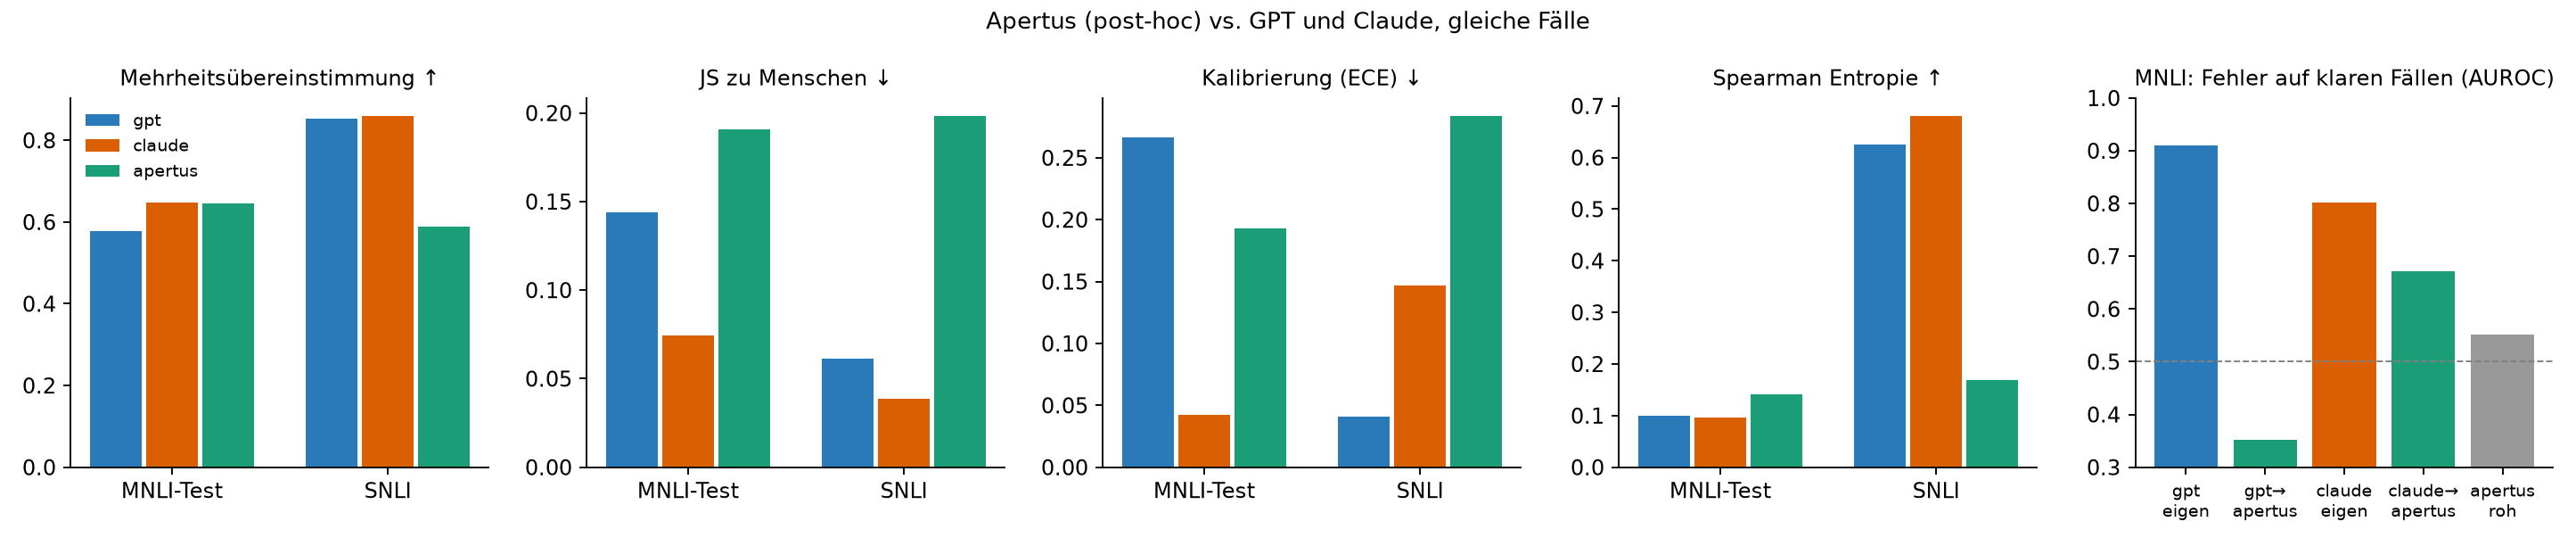

Alle Tabellen: extension_apertus/results


In [6]:
display(Image(filename=str(ev.RESULTS / "apertus_vergleich.png")))
print("Alle Tabellen:", ev.RESULTS.relative_to(ROOT))

## 6 · Siegel nachher prüfen

In [7]:
record, changed, missing, added = verify_freeze.check(ROOT)
assert not (changed or missing or added), "Eingefrorene Dateien wurden verändert!"
print("Siegel weiterhin OK: die Erweiterung hat nichts am eingefrorenen Projekt verändert.")

Siegel weiterhin OK: die Erweiterung hat nichts am eingefrorenen Projekt verändert.


## 7 · Einordnung (Stand 7.11.2026, 500 Bootstrap-Wiederholungen)

- **MNLI:** Apertus trifft die menschliche Mehrheit gleich oft wie Claude (0.645 vs. 0.648) und etwas öfter als GPT (+0.068, CI knapp über 0). Seine Wahrscheinlichkeiten sind aber am weitesten von den Menschen entfernt (JS 0.191) und die Konfidenz ist mittelmässig kalibriert (ECE 0.19; GPT 0.27, Claude 0.04).
- **Gegenteiliges Fehlerprofil:** GPT irrt auf klaren Fällen fast nur bei der Antwort «neutral». Apertus irrt bei «contradiction» und «entailment», meist dort, wo die Mehrheit «neutral» sagt, und das mit hoher Konfidenz.
- **Transfer:** Der GPT-Risikobaum rankt Apertus-Fehler *schlechter als Zufall* (MNLI 0.35, SNLI 0.23). Erwartung bestätigt. Der Claude-Risikobaum überträgt auf MNLI teilweise (0.67, besser als Apertus' eigene Konfidenz), auf SNLI nicht.
- **SNLI:** Apertus bricht ein (Mehrheit 0.59 vs. 0.85 / 0.86): 52 der 78 Abweichungen auf klaren Fällen sind «entailment», wo Menschen «neutral» sagen.
- **Deutung:** Die Bewerter lernen, *hinter welchem Label* ein bestimmtes Modell seine Fehler versteckt. Das ist modellspezifisch und überträgt nicht auf ein Modell mit anderem Fehlerprofil.
- **Vorbehalte:** explorativ, kleine Fehlerzahlen (MNLI 19 Apertus-Abweichungen auf klaren Fällen), Formatanweisung per Text statt Schema, 17 bzw. 6 Fälle ausgeschlossen (fast alle mit menschlicher Mehrheit «neutral», also eher zugunsten von Apertus).